# NASA Kepler Objects of Interest
## Exoplanet Candidate Classification

### 1. Project Introduction

The NASA Kepler dataset contains observations of potential exoplanets, including measurements related to orbital characteristics, transit signals, and stellar properties.

The objective of this project is to develop a machine-learning model that distinguishes promising exoplanet observations from false-positive detections.

This notebook focuses on the **data exploration and preprocessing** stages of the project. Specifically, we aim to:

- Understand the dataset and its classification labels.
- Identify and exclude variables that may introduce data leakage.
- Select relevant astronomical measurements for model training.
- Investigate missing values, outliers, and relationships between features.
- Prepare a consistent dataset for subsequent machine-learning experiments.

The prepared data will be used by the other team members for model training, performance evaluation, and error analysis.

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



### 2. Dataset Loading and Initial Inspection

**Objective:** Load the NASA Kepler Objects of Interest dataset and examine its structure.

We begin by importing the dataset and inspecting its dimensions, column names, and first few observations. This allows us to understand how the data is organized and identify the types of information available for analysis.

The dataset contains **9,564 observations and 153 original variables**, including planetary measurements, stellar properties, transit signal characteristics, and classification information.

In [2]:

# Download the Kepler dataset from NASA
import requests
from io import StringIO

url = "https://exoplanetarchive.ipac.caltech.edu/TAP/sync"
query = "SELECT * FROM cumulative"
params = {"query": query, "format": "csv"}

response = requests.get(url, params=params, timeout=120)
response.raise_for_status()

# Turn the downloaded text into a table
df = pd.read_csv(StringIO(response.text))

print("Dataset shape:", df.shape)
display(df.head())

# Save a copy of the original data
df.to_csv("kepler_raw.csv", index=False)


Dataset shape: (9564, 153)


,kepid,kepoi_name,kepler_name,ra,ra_err,ra_str,dec,dec_err,dec_str,koi_gmag,...,koi_fpflag_co,koi_fpflag_ec,koi_insol,koi_insol_err1,koi_insol_err2,koi_srho,koi_srho_err1,koi_srho_err2,koi_fittype,koi_score
0,10797460,K00752.01,Kepler-227 b,291.93423,0.0,19h27m44.22s,48.141651,0.0,+48d08m29.9s,15.890,...,0,0,93.59,29.45,-16.65,3.20796,0.33173,-1.09986,LS+MCMC,1.000
1,10797460,K00752.02,Kepler-227 c,291.93423,0.0,19h27m44.22s,48.141651,0.0,+48d08m29.9s,15.890,...,0,0,9.11,2.87,-1.62,3.02368,2.20489,-2.49638,LS+MCMC,0.969
2,10811496,K00753.01,NaN,297.00482,0.0,19h48m01.16s,48.134129,0.0,+48d08m02.9s,15.943,...,0,0,39.30,31.04,-10.49,7.29555,35.03293,-2.75453,LS+MCMC,0.000
3,10848459,K00754.01,NaN,285.53461,0.0,19h02m08.31s,48.285210,0.0,+48d17m06.8s,16.100,...,0,0,891.96,668.95,-230.35,0.22080,0.00917,-0.01837,LS+MCMC,0.000
4,10854555,K00755.01,Kepler-664 b,288.75488,0.0,19h15m01.17s,48.226200,0.0,+48d13m34.3s,16.015,...,0,0,926.16,874.33,-314.24,1.98635,2.71141,-1.74541,LS+MCMC,1.000


### 3. Target Variable Analysis

**Objective:** Examine the distribution of classification labels and define the prediction target.

The original dataset classifies observations into three categories:

- **CONFIRMED:** Objects identified as confirmed exoplanets.
- **CANDIDATE:** Objects considered potential exoplanets but not yet confirmed.
- **FALSE POSITIVE:** Observations determined not to represent genuine exoplanet detections.

For this project, we formulate a binary classification problem by combining confirmed planets and candidates into one class.

The resulting target variable is:

- **0 — False Positive:** 4,839 observations (50.60%).
- **1 — Promising Planet Observation:** 4,725 observations (49.40%).

The two classes are nearly balanced, reducing the immediate need for class-resampling techniques. However, both precision and recall will remain important evaluation metrics.

Classification counts:
koi_disposition
FALSE POSITIVE    4839
CONFIRMED         2748
CANDIDATE         1977
Name: count, dtype: int64

Classification percentages:
koi_disposition
FALSE POSITIVE    50.60
CONFIRMED         28.73
CANDIDATE         20.67
Name: count, dtype: float64


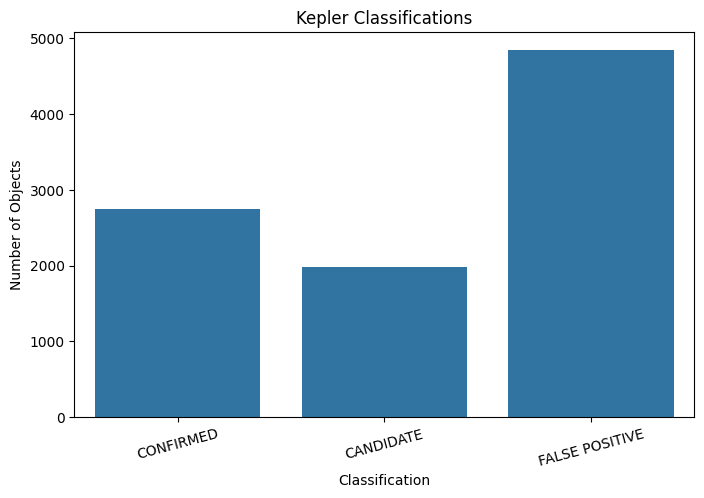

In [3]:

# Count the three NASA classifications
counts = df["koi_disposition"].value_counts()
print("Classification counts:")
print(counts)

# Calculate percentages
percentages = counts / len(df) * 100
print("\nClassification percentages:")
print(percentages.round(2))

# Draw a simple bar chart
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="koi_disposition")
plt.title("Kepler Classifications")
plt.xlabel("Classification")
plt.ylabel("Number of Objects")
plt.xticks(rotation=15)
plt.show()


In [4]:

# Create the new binary target column
labels = {"FALSE POSITIVE": 0, "CONFIRMED": 1, "CANDIDATE": 1}
df["target"] = df["koi_disposition"].map(labels)

print("Binary target counts:")
print(df["target"].value_counts())
print("\nMissing targets:", df["target"].isna().sum())


Binary target counts:
target
0    4839
1    4725
Name: count, dtype: int64

Missing targets: 0


### 4. Data Leakage Investigation

**Objective:** Identify variables that could artificially inflate model performance by revealing the classification outcome.

Data leakage occurs when a model uses information that would not realistically be available at prediction time.

In the Kepler dataset, certain variables directly reflect scientific vetting and classification decisions. Examples include `koi_pdisposition`, `koi_score`, and the false-positive diagnostic flags.

We inspect suspicious variables by examining their missing-value percentages, unique values, and sample observations.

Based on this investigation, classification-related fields, identifiers, and certain processing metadata are excluded from the preliminary feature dataset.

After these exclusions, **137 preliminary features remain**. These features require further auditing before being used for model training.

In [5]:

# List the columns that might reveal the classification
suspicious_columns = [
    "koi_disposition", "koi_pdisposition", "koi_score",
    "koi_fpflag_nt", "koi_fpflag_ss", "koi_fpflag_co", "koi_fpflag_ec",
    "koi_comment", "koi_disp_prov", "koi_vet_stat", "koi_vet_date",
    "kepler_name"
]

# Make a simple summary table
rows = []
for column in suspicious_columns:
    if column in df.columns:
        missing = df[column].isna().sum() / len(df) * 100
        unique = df[column].nunique()
        rows.append([column, round(missing, 2), unique])

summary = pd.DataFrame(rows, columns=["Column", "Missing %", "Unique Values"])
display(summary)

# Look at the first five rows of these columns
existing_columns = summary["Column"].tolist()
display(df[existing_columns].head())


,Column,Missing %,Unique Values
0,koi_disposition,0.00,3
1,koi_pdisposition,0.00,2
2,koi_score,15.79,650
3,koi_fpflag_nt,0.00,3
4,koi_fpflag_ss,0.00,2
5,koi_fpflag_co,0.00,2
6,koi_fpflag_ec,0.00,2
7,koi_comment,12.64,995
8,koi_disp_prov,0.00,1
9,koi_vet_stat,0.00,1


,koi_disposition,koi_pdisposition,koi_score,koi_fpflag_nt,koi_fpflag_ss,koi_fpflag_co,koi_fpflag_ec,koi_comment,koi_disp_prov,koi_vet_stat,koi_vet_date,kepler_name
0,CONFIRMED,CANDIDATE,1.000,0,0,0,0,NO_COMMENT,q1_q17_dr25_sup_koi,Done,2018-08-16 00:00:00,Kepler-227 b
1,CONFIRMED,CANDIDATE,0.969,0,0,0,0,NO_COMMENT,q1_q17_dr25_sup_koi,Done,2018-08-16 00:00:00,Kepler-227 c
2,CANDIDATE,CANDIDATE,0.000,0,0,0,0,DEEP_V_SHAPED,q1_q17_dr25_sup_koi,Done,2018-08-16 00:00:00,NaN
3,FALSE POSITIVE,FALSE POSITIVE,0.000,0,1,0,0,MOD_ODDEVEN_DV---MOD_ODDEVEN_ALT---DEEP_V_SHAPED,q1_q17_dr25_sup_koi,Done,2018-08-16 00:00:00,NaN
4,CONFIRMED,CANDIDATE,1.000,0,0,0,0,NO_COMMENT,q1_q17_dr25_sup_koi,Done,2018-08-16 00:00:00,Kepler-664 b


In [6]:

# Remove classification-related columns from the input features
leakage_columns = [
    "koi_disposition", "koi_pdisposition", "koi_score",
    "koi_fpflag_nt", "koi_fpflag_ss", "koi_fpflag_co", "koi_fpflag_ec",
    "koi_comment", "koi_disp_prov", "koi_vet_stat", "koi_vet_date",
    "kepler_name"
]

# Do not use identifiers as input features
identifier_columns = [
    "kepid", "kepoi_name", "koi_tce_plnt_num", "koi_tce_delivname"
]

# Keep the labels separate from the input features
y = df["target"].copy()

# Drop these columns from a copy, not from the original df
columns_to_remove = leakage_columns + identifier_columns + ["target"]
X = df.drop(columns=columns_to_remove, errors="ignore").copy()

print("Original dataset:", df.shape)
print("Preliminary features:", X.shape)
print("Target:", y.shape)
print("\nRemaining columns:")
print(X.columns.tolist())



Original dataset: (9564, 154)
Preliminary features: (9564, 137)
Target: (9564,)

Remaining columns:
['ra', 'ra_err', 'ra_str', 'dec', 'dec_err', 'dec_str', 'koi_gmag', 'koi_gmag_err', 'koi_rmag', 'koi_rmag_err', 'koi_imag', 'koi_imag_err', 'koi_zmag', 'koi_zmag_err', 'koi_jmag', 'koi_jmag_err', 'koi_hmag', 'koi_hmag_err', 'koi_kmag', 'koi_kmag_err', 'koi_kepmag', 'koi_kepmag_err', 'koi_delivname', 'koi_quarters', 'koi_count', 'koi_num_transits', 'koi_max_sngle_ev', 'koi_max_mult_ev', 'koi_bin_oedp_sig', 'koi_limbdark_mod', 'koi_ldm_coeff4', 'koi_ldm_coeff3', 'koi_ldm_coeff2', 'koi_ldm_coeff1', 'koi_trans_mod', 'koi_model_snr', 'koi_model_dof', 'koi_model_chisq', 'koi_time0bk', 'koi_time0bk_err1', 'koi_time0bk_err2', 'koi_eccen', 'koi_eccen_err1', 'koi_eccen_err2', 'koi_longp', 'koi_longp_err1', 'koi_longp_err2', 'koi_prad', 'koi_prad_err1', 'koi_prad_err2', 'koi_sma', 'koi_sma_err1', 'koi_sma_err2', 'koi_impact', 'koi_impact_err1', 'koi_impact_err2', 'koi_duration', 'koi_duration_err1'

### 5. Scientific Feature Selection

**Objective:** Select an interpretable set of astronomical measurements for the initial classification model.

Rather than using all 137 preliminary variables, we select 19 numerical features describing the observed transit, estimated planetary characteristics, and properties of the host star.

The selected variables include orbital period, transit duration and depth, signal-to-noise ratio, planetary radius, stellar temperature, stellar radius, and additional astronomical measurements.

This selection provides a manageable baseline for comparing machine-learning algorithms and interpreting model behavior.

The resulting feature matrix contains **9,564 observations and 19 numerical features**.

**Methodological limitation:** Some features are derived from fitted astronomical models. Their availability and potential dependence on prior scientific processing should therefore be considered when interpreting performance on newly observed objects.

In [7]:

# Choose 19 scientific measurements
selected_features = [
    "koi_period", "koi_duration", "koi_depth", "koi_model_snr",
    "koi_impact", "koi_ror", "koi_dor",
    "koi_prad", "koi_sma", "koi_teq", "koi_insol",
    "koi_steff", "koi_slogg", "koi_srad", "koi_smass", "koi_smet",
    "koi_num_transits", "koi_max_sngle_ev", "koi_max_mult_ev"
]

# Select only these columns
X_selected = X[selected_features].copy()

print("Selected features:", len(selected_features))
print("Dataset shape:", X_selected.shape)
display(X_selected.head())


# Create scientific feature dataset
X_selected = X[selected_features].copy()

print("Selected features:", X_selected.shape[1])
print("Dataset shape:", X_selected.shape)

display(X_selected.head())


Selected features: 19
Dataset shape: (9564, 19)


,koi_period,koi_duration,koi_depth,koi_model_snr,koi_impact,koi_ror,koi_dor,koi_prad,koi_sma,koi_teq,koi_insol,koi_steff,koi_slogg,koi_srad,koi_smass,koi_smet,koi_num_transits,koi_max_sngle_ev,koi_max_mult_ev
0,9.488036,2.95750,615.8,35.8,0.146,0.022344,24.810,2.26,0.0853,793.0,93.59,5455.0,4.467,0.927,0.919,0.14,142.0,5.135849,28.470820
1,54.418383,4.50700,874.8,25.8,0.586,0.027954,77.900,2.83,0.2734,443.0,9.11,5455.0,4.467,0.927,0.919,0.14,25.0,7.027669,20.109507
2,19.899140,1.78220,10829.0,76.3,0.969,0.154046,53.500,14.60,0.1419,638.0,39.30,5853.0,4.544,0.868,0.961,-0.18,56.0,37.159767,187.449100
3,1.736952,2.40641,8079.2,505.6,1.276,0.387394,3.278,33.46,0.0267,1395.0,891.96,5805.0,4.564,0.791,0.836,-0.52,621.0,39.066550,541.895100
4,2.525592,1.65450,603.3,40.9,0.701,0.024064,8.750,2.75,0.0374,1406.0,926.16,6031.0,4.438,1.046,1.095,0.07,515.0,4.749945,33.191900


Selected features: 19
Dataset shape: (9564, 19)


,koi_period,koi_duration,koi_depth,koi_model_snr,koi_impact,koi_ror,koi_dor,koi_prad,koi_sma,koi_teq,koi_insol,koi_steff,koi_slogg,koi_srad,koi_smass,koi_smet,koi_num_transits,koi_max_sngle_ev,koi_max_mult_ev
0,9.488036,2.95750,615.8,35.8,0.146,0.022344,24.810,2.26,0.0853,793.0,93.59,5455.0,4.467,0.927,0.919,0.14,142.0,5.135849,28.470820
1,54.418383,4.50700,874.8,25.8,0.586,0.027954,77.900,2.83,0.2734,443.0,9.11,5455.0,4.467,0.927,0.919,0.14,25.0,7.027669,20.109507
2,19.899140,1.78220,10829.0,76.3,0.969,0.154046,53.500,14.60,0.1419,638.0,39.30,5853.0,4.544,0.868,0.961,-0.18,56.0,37.159767,187.449100
3,1.736952,2.40641,8079.2,505.6,1.276,0.387394,3.278,33.46,0.0267,1395.0,891.96,5805.0,4.564,0.791,0.836,-0.52,621.0,39.066550,541.895100
4,2.525592,1.65450,603.3,40.9,0.701,0.024064,8.750,2.75,0.0374,1406.0,926.16,6031.0,4.438,1.046,1.095,0.07,515.0,4.749945,33.191900


### 6. Missing Data Analysis

#### 6A. Quantifying Missing Values

**Objective:** Determine the extent of missing data across the selected astronomical features.

Missing measurements are common in observational datasets because some signals may be difficult to detect or certain parameters may not be estimated reliably.

Our analysis shows that:

- 8,305 observations (86.84%) have complete measurements.
- 1,259 observations (13.16%) contain at least one missing value.
- Three features, `koi_max_sngle_ev`, `koi_num_transits`, and `koi_max_mult_ev`, each have 11.94% missing values.
- Orbital period and transit duration contain no missing values.

We retain incomplete observations for further investigation rather than immediately removing them.

In [8]:

missing_summary = pd.DataFrame({
    "Missing Count": X_selected.isna().sum(),
    "Missing %": (
        X_selected.isna().mean() * 100
    ).round(2),
    "Data Type": X_selected.dtypes
})

missing_summary = missing_summary.sort_values(
    "Missing %",
    ascending=False
)

display(missing_summary)

print(
    "Rows with at least one missing value:",
    X_selected.isna().any(axis=1).sum()
)

print(
    "Rows with complete measurements:",
    X_selected.notna().all(axis=1).sum()
)


,Missing Count,Missing %,Data Type
koi_max_sngle_ev,1142,11.94,float64
koi_num_transits,1142,11.94,float64
koi_max_mult_ev,1142,11.94,float64
koi_smet,386,4.04,float64
koi_smass,363,3.80,float64
koi_depth,363,3.80,float64
koi_teq,363,3.80,float64
koi_model_snr,363,3.80,float64
koi_impact,363,3.80,float64
koi_ror,363,3.80,float64


Rows with at least one missing value: 1259
Rows with complete measurements: 8305


#### 6B. Visualizing Missing Data

**Objective:** Visualize which astronomical features contain the highest proportions of missing measurements.

A horizontal bar chart is used to compare missing-value percentages across the selected features.

This visualization helps identify which variables may require greater attention during preprocessing and provides an overview of the dataset's completeness.

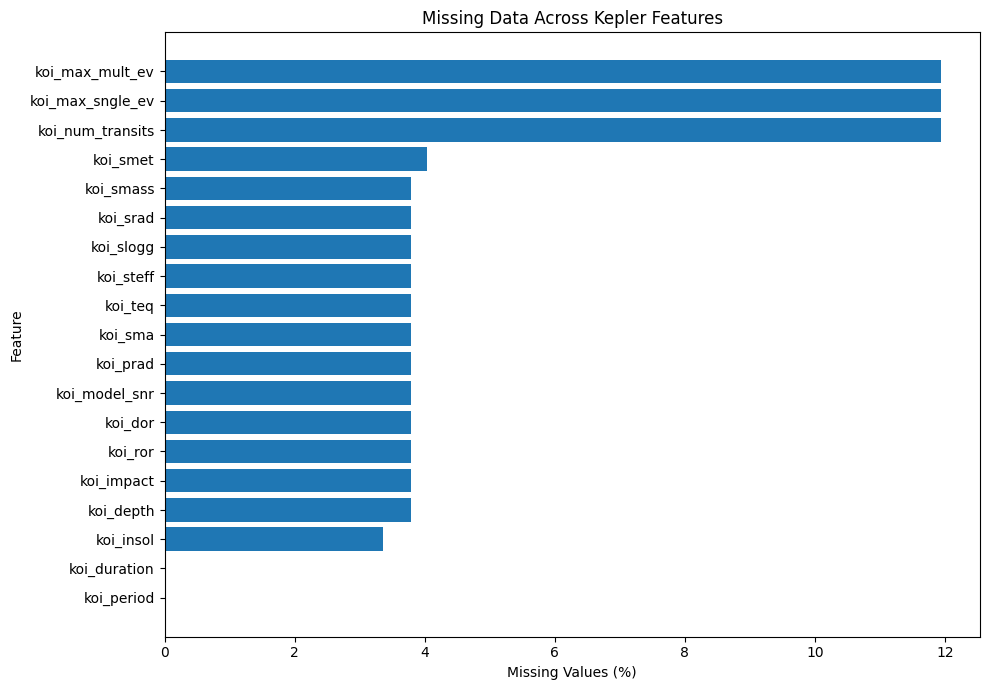

In [9]:

# Find the missing percentage for each feature
missing_percent = X_selected.isna().mean() * 100
missing_percent = missing_percent.sort_values()

# Draw a horizontal bar chart
plt.figure(figsize=(10, 7))
plt.barh(missing_percent.index, missing_percent.values)
plt.xlabel("Missing Values (%)")
plt.ylabel("Feature")
plt.title("Missing Data Across Kepler Features")
plt.tight_layout()
plt.savefig("kepler_missing_values.png", dpi=300)
plt.show()


#### 6C. Comparing Missingness Across Classes

**Objective:** Investigate whether missing measurements are distributed differently between false positives and promising planet observations.

We calculate the percentage of missing values for each feature separately within the two target classes.

This analysis helps determine whether missingness is associated with classification outcomes and whether missing-value indicators could be useful during model development.

Any differences observed will be interpreted as associations rather than evidence of a causal relationship.

In [10]:

# Calculate missing percentages separately for the two classes
false_positive = X_selected[y == 0]
promising_planet = X_selected[y == 1]

false_missing = false_positive.isna().mean() * 100
promising_missing = promising_planet.isna().mean() * 100

# Make a comparison table
missing_by_class = pd.DataFrame({
    "False Positive": false_missing,
    "Promising Planet": promising_missing
})

# Find the absolute percentage-point difference
missing_by_class["Difference"] = abs(
    missing_by_class["False Positive"] - missing_by_class["Promising Planet"]
)

missing_by_class = missing_by_class.sort_values("Difference", ascending=False)
display(missing_by_class.round(2))


,False Positive,Promising Planet,Difference
koi_max_sngle_ev,13.83,10.01,3.81
koi_num_transits,13.83,10.01,3.81
koi_max_mult_ev,13.83,10.01,3.81
koi_smet,5.72,2.31,3.42
koi_smass,5.31,2.24,3.07
koi_depth,5.31,2.24,3.07
koi_teq,5.31,2.24,3.07
koi_model_snr,5.31,2.24,3.07
koi_impact,5.31,2.24,3.07
koi_ror,5.31,2.24,3.07


Findings and Interpretation

The missing-data analysis revealed differences between the two classification groups. Across all features containing missing values, false-positive observations exhibited higher missingness rates than promising planet observations.

The largest differences were observed in koi_max_sngle_ev, koi_num_transits, and koi_max_mult_ev, with missingness rates of 13.83% for false positives and 10.01% for promising planets, a difference of approximately 3.81 percentage points.

Several other astronomical measurements, including transit depth, signal-to-noise ratio, and stellar properties, showed similar differences of approximately 3.07 percentage points.

In contrast, orbital period and transit duration had no missing values in either class.

These findings suggest that missingness patterns are associated with the classification outcome and may contain useful predictive information. However, further investigation is needed to determine whether these patterns reflect observational limitations or differences in data processing.

The higher missingness rates among false positives suggest that missing-data patterns may themselves contain predictive information. However, this relationship should be interpreted cautiously, as it could reflect differences in observation quality or data-processing procedures rather than intrinsic astronomical characteristics.

Another observation is that several features share identical missingness percentages across both classes. This suggests that their missing values may occur together, potentially because they are derived from related measurements or fitting procedures. Further analysis would be needed to confirm this relationship.

Importantly, missing measurements should not automatically be interpreted as weak detection signals. Additional analysis of signal strength and measurement availability would be required to establish such a relationship.

Finally, because missingness is associated with the target variable, it may introduce unintended bias into the classification model. A useful future experiment would be to compare model performance with and without missingness indicators to investigate whether the model relies on these patterns.

#### 6D. Missing Data Handling Strategy

**Objective:** Determine an appropriate strategy for handling missing measurements while minimizing information loss and preventing data leakage.

Our analysis revealed that 13.16% of observations contain at least one missing measurement. Rather than removing these observations, we decided to retain all 9,564 records to preserve potentially useful information.

We selected **median imputation** as our initial approach because astronomical measurements may contain extreme values and skewed distributions. The median is less sensitive to outliers than the mean.

To prevent data leakage, missing values will be imputed only after splitting the dataset into training and testing sets. The median values will be calculated using the training data and subsequently applied to the test data.

This preprocessing strategy will be implemented within a machine-learning pipeline during model development.

In [11]:


# 6D - Missing Data Handling Strategy

# Count rows that have at least one missing value
rows_with_missing = X_selected.isna().any(axis=1).sum()

# Create a summary table
preprocessing_summary = pd.DataFrame({
    "Decision": [
        "Original observations",
        "Selected features",
        "Rows with missing values",
        "Missing-value strategy",
        "When to fit imputation",
        "Outlier handling",
        "Data leakage prevention"
    ],
    "Approach": [
        len(X_selected),
        X_selected.shape[1],
        rows_with_missing,
        "Median imputation (planned)",
        "Training data only",
        "Investigate during EDA",
        "Use training-fitted transformations"
    ]
})

# Display the table
display(preprocessing_summary)


,Decision,Approach
0,Original observations,9564
1,Selected features,19
2,Rows with missing values,1259
3,Missing-value strategy,Median imputation (planned)
4,When to fit imputation,Training data only
5,Outlier handling,Investigate during EDA
6,Data leakage prevention,Use training-fitted transformations


### 7. Exploratory Data Analysis (EDA)

#### 7A. Feature Distribution Analysis

**Objective:** Examine the distributions of the 19 selected astronomical features and identify unusual patterns or extreme values.

We use histograms to understand how the measurements are distributed across the Kepler dataset.

Specifically, we want to investigate:

- Whether features are symmetrically distributed or skewed.
- Whether some measurements contain unusually large or small values.
- Whether the features have different numerical scales.
- Whether transformations or scaling may be necessary during model training.

This analysis will help us understand the dataset and make informed preprocessing decisions.

At this stage, we only visualize the data. No values are modified or removed.

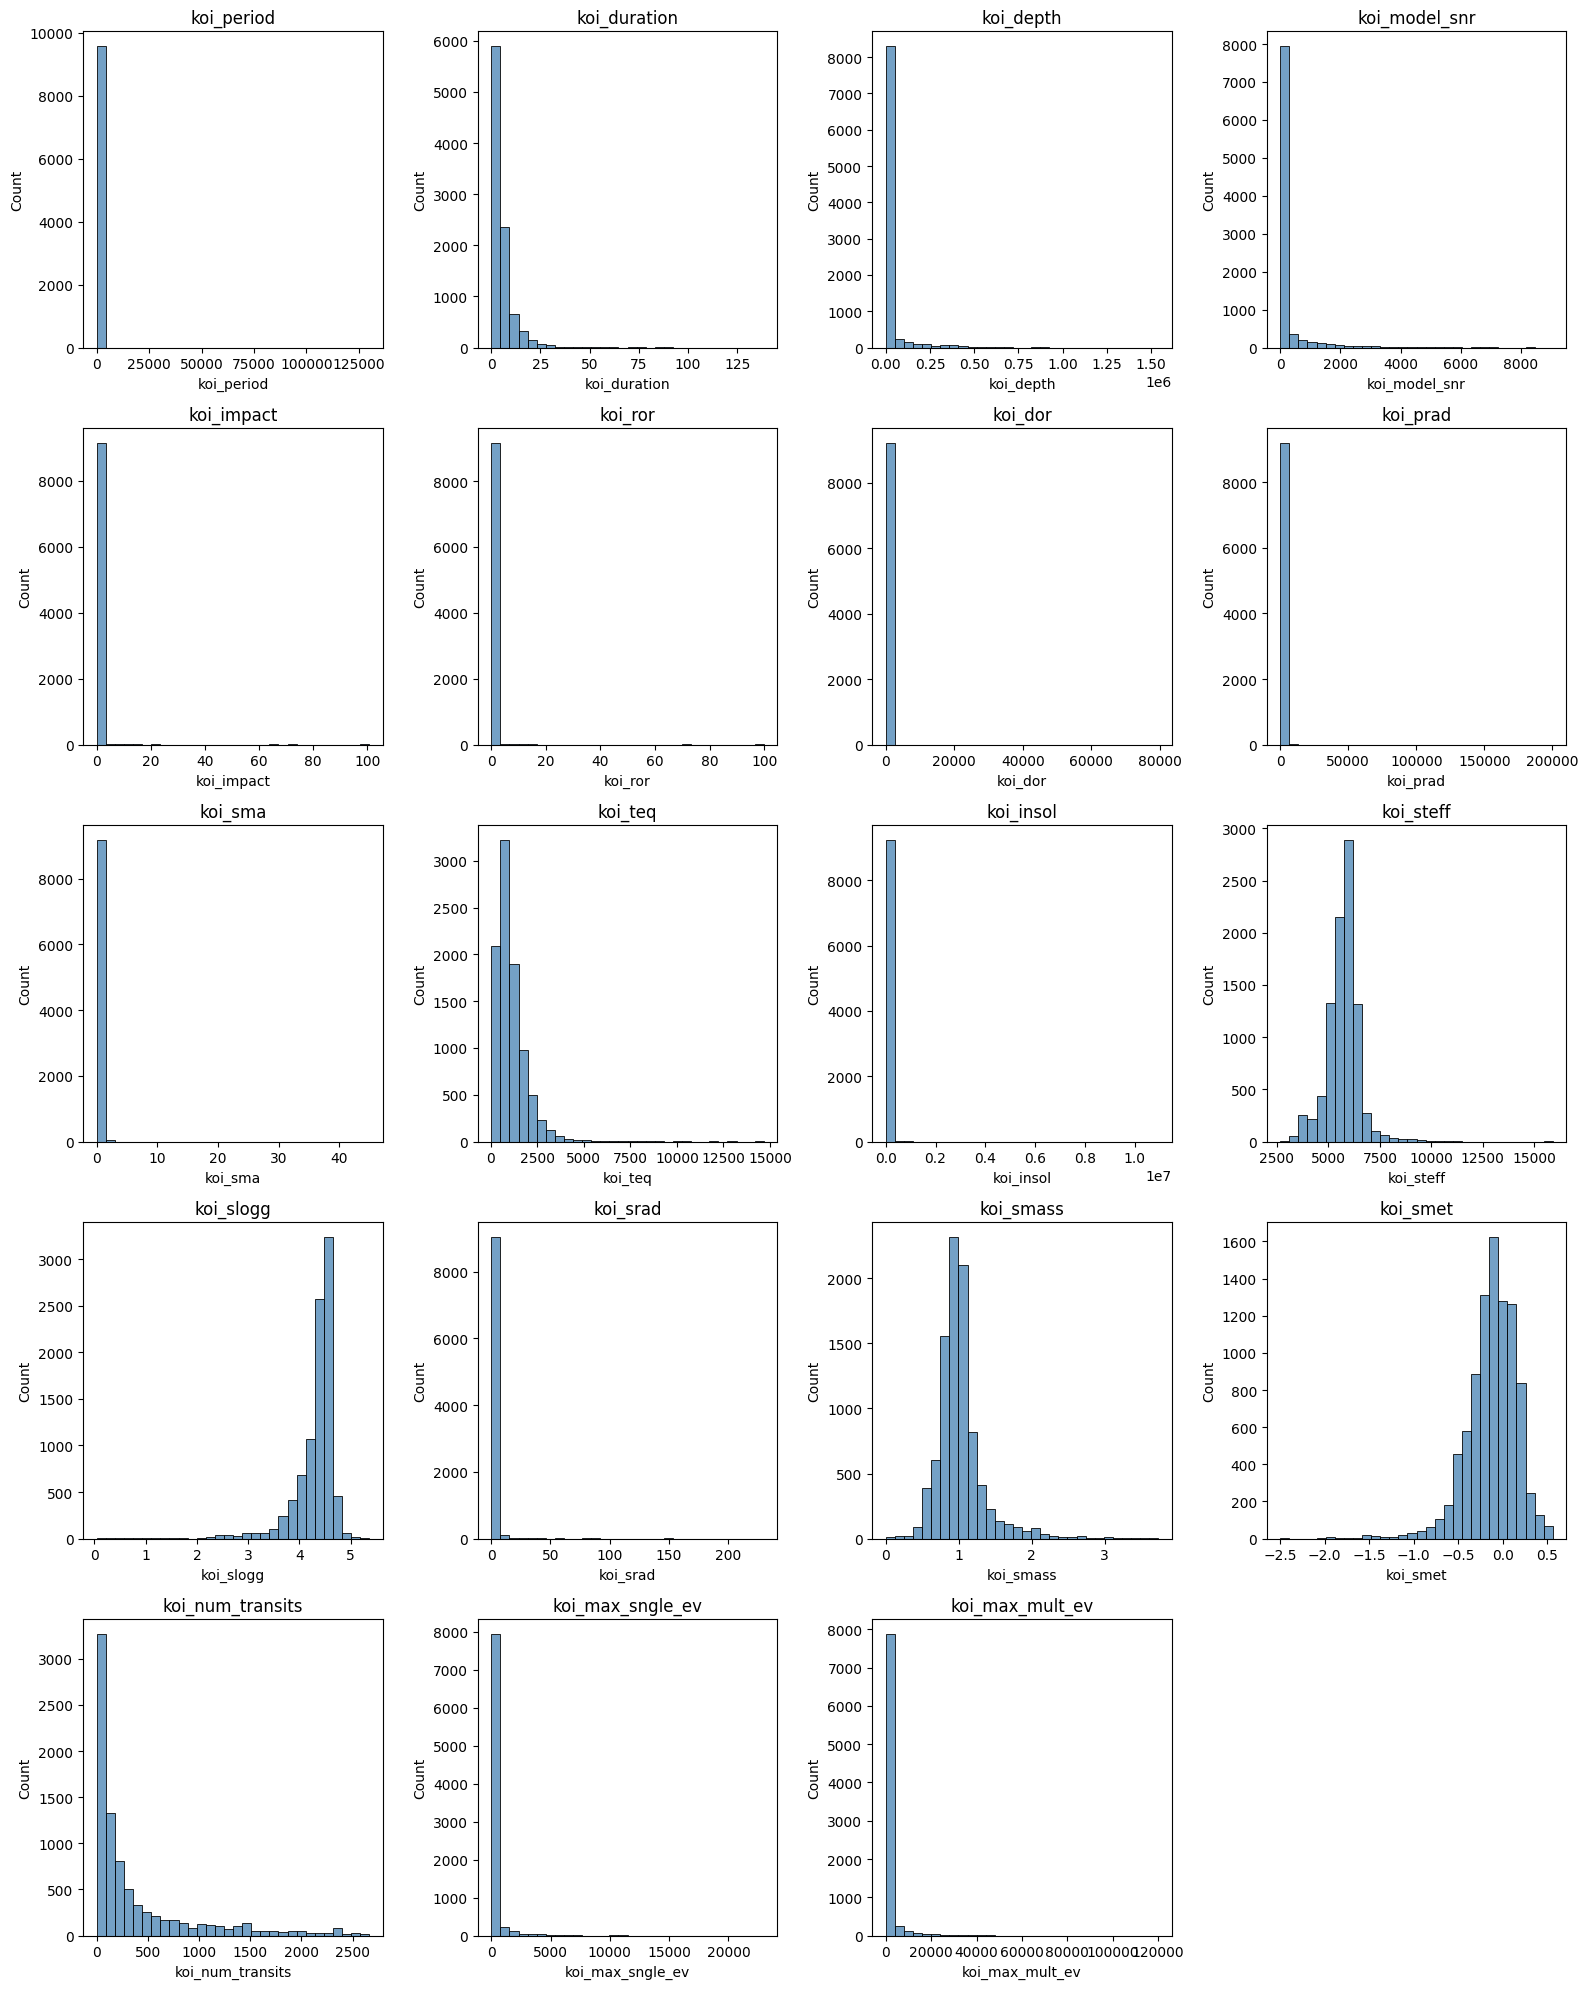

In [12]:

# 7A - Feature Distribution Analysis

# Create a large figure for all 19 features
plt.figure(figsize=(16, 20))

# Go through each feature
for i, column in enumerate(X_selected.columns):

    # Create a subplot
    plt.subplot(5, 4, i + 1)

    # Draw the histogram
    sns.histplot(
        X_selected[column].dropna(),
        bins=30,
        color="steelblue"
    )

    # Add the feature name
    plt.title(column)
    plt.xlabel(column)
    plt.ylabel("Count")

# Make the plots fit nicely
plt.tight_layout()

# Save the figure
plt.savefig("kepler_feature_distributions.png", dpi=300)

# Display the figure
plt.show()



#### 7A. Findings and Interpretation

The feature distributions reveal that many astronomical measurements are highly right-skewed, including orbital period (`koi_period`), transit depth (`koi_depth`), planetary radius (`koi_prad`), and signal-to-noise ratio (`koi_model_snr`).

Most observations are concentrated at relatively small values, while a limited number of observations have extremely large measurements. These extreme values stretch the horizontal axes and make the distributions of typical observations difficult to distinguish.

In contrast, stellar temperature (`koi_steff`) and stellar mass (`koi_smass`) appear more concentrated around central values. Stellar surface gravity (`koi_slogg`) and metallicity (`koi_smet`) show different, less symmetric distributions.

These findings suggest that the dataset contains substantial differences in feature scales and potential outliers. Such characteristics may affect algorithms sensitive to feature magnitude and distribution, particularly Logistic Regression and Support Vector Machines.

Further investigation is necessary before deciding whether extreme observations should be transformed, retained, or treated as potential data-quality issues. No observations are removed at this stage.

#### 7B. Outlier Analysis

**Objective:** Identify and examine unusually large or small astronomical measurements.

The histograms in Section 7A revealed that several features contain extreme values. We now use boxplots to examine these observations more closely.

Boxplots display the median, quartiles, and potential outliers for each feature.

Outliers are important in this dataset because they may represent unusual astronomical systems, measurement errors, or false-positive detections.

However, an extreme measurement is not necessarily incorrect. We therefore investigate potential outliers without automatically removing them from the dataset.

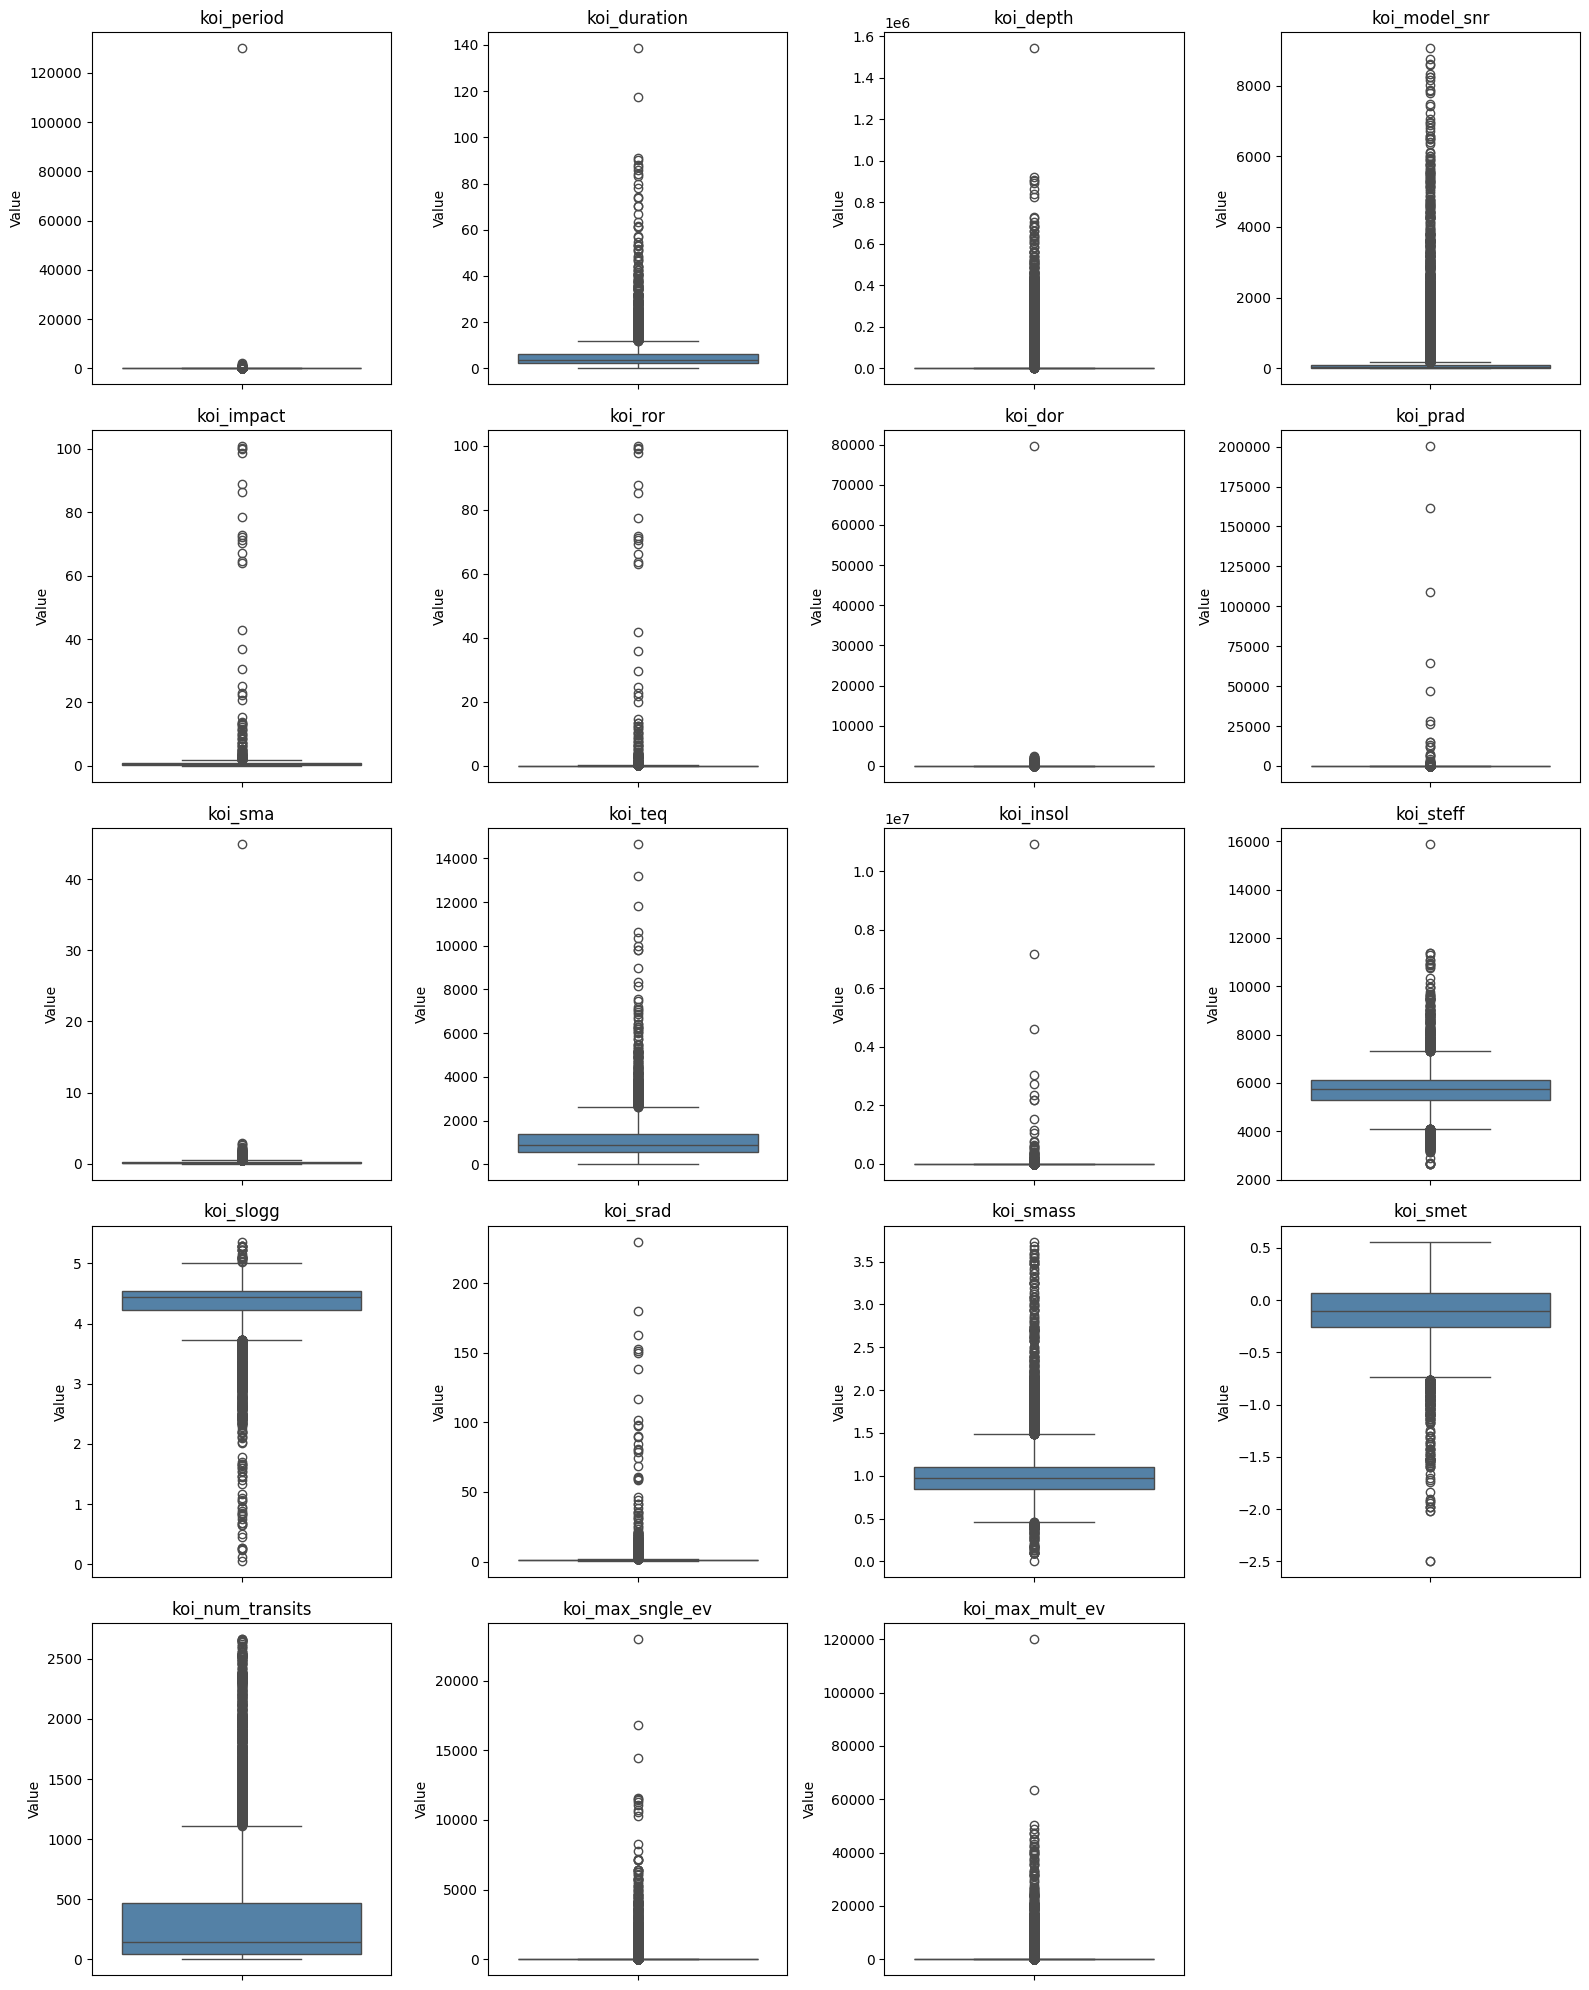

In [13]:

# 7B - Outlier Analysis

# Create a figure
plt.figure(figsize=(16, 20))

# Go through all 19 features
for i, column in enumerate(X_selected.columns):

    # Create a subplot
    plt.subplot(5, 4, i + 1)

    # Draw a boxplot
    sns.boxplot(
        y=X_selected[column],
        color="steelblue"
    )

    plt.title(column)
    plt.ylabel("Value")

# Adjust spacing
plt.tight_layout()

# Save figure
plt.savefig("kepler_boxplots.png", dpi=300)

# Display figure
plt.show()


#### 7B. Findings and Interpretation

The boxplots confirm that many of the selected astronomical features contain numerous potential outliers, particularly orbital period (`koi_period`), planetary radius (`koi_prad`), transit depth (`koi_depth`), and signal-to-noise ratio (`koi_model_snr`).

Several features exhibit extreme upper-end values that are substantially larger than the majority of observations. These extreme measurements compress the central portions of the boxplots, making it difficult to observe the spread of typical values.

Stellar temperature (`koi_steff`) and stellar mass (`koi_smass`) have relatively concentrated central distributions, while stellar surface gravity (`koi_slogg`) and metallicity (`koi_smet`) show notable lower-end outliers.

Some unusually large planetary or orbital measurements may reflect unusual astronomical systems, unreliable fitted parameters, or false-positive detections. However, the boxplots alone cannot determine their causes.

Since outliers may contain scientifically meaningful information, we will retain all observations at this stage rather than automatically removing them. Further analysis will investigate their numerical ranges and relationships with the classification labels.

#### 7C. Numerical Outlier Investigation

**Objective:** Examine the numerical ranges of the selected astronomical features to better understand the extreme values observed in the histograms and boxplots.

We calculate the minimum, median, 95th percentile, and maximum values of each feature.

Comparing these statistics allows us to assess how far the largest observations are from typical values and identify features that may require additional investigation.

This analysis does not modify the dataset or remove any observations.

In [14]:

# 7C - Numerical Outlier Investigation

# Create an empty table
outlier_summary = pd.DataFrame()

# Calculate statistics for each feature
outlier_summary["Minimum"] = X_selected.min()
outlier_summary["Median"] = X_selected.median()
outlier_summary["95th Percentile"] = X_selected.quantile(0.95)
outlier_summary["Maximum"] = X_selected.max()

# Round values for readability
outlier_summary = outlier_summary.round(2)

# Display the table
display(outlier_summary)


,Minimum,Median,95th Percentile,Maximum
koi_period,0.24,9.75,371.56,129995.78
koi_duration,0.05,3.79,16.03,138.54
koi_depth,0.00,421.10,172404.00,1541400.00
koi_model_snr,0.00,23.00,1550.90,9054.70
koi_impact,0.00,0.54,1.25,100.81
koi_ror,0.00,0.02,0.55,99.87
koi_dor,0.37,15.46,321.60,79614.00
koi_prad,0.08,2.39,87.21,200346.00
koi_sma,0.01,0.09,1.02,44.99
koi_teq,25.00,878.00,2545.00,14667.00


#### 7C. Findings and Interpretation

The numerical analysis confirms the presence of extreme values across several astronomical features.

For example, the median planetary radius (`koi_prad`) is 2.39 Earth radii, while the maximum reaches 200,346 Earth radii. Similarly, orbital period (`koi_period`) has a median of 9.75 days but a maximum of approximately 129,996 days.

Other variables, including transit depth (`koi_depth`), signal-to-noise ratio (`koi_model_snr`), and stellar radius (`koi_srad`), also exhibit substantial differences between their median and maximum values.

These findings indicate that several features are strongly right-skewed and that a small number of observations have unusually large fitted measurements.

Such values may represent unusual astronomical systems, unreliable parameter estimates, or false-positive detections. However, their causes cannot be determined from summary statistics alone.

We will retain these observations for now and investigate how extreme measurements relate to the classification labels before deciding whether any preprocessing adjustments are appropriate.

#### 7D. Feature Correlation Analysis

**Objective:** Examine relationships between the selected astronomical features and identify variables that may contain overlapping information.

We calculate the Pearson correlation coefficients between the 19 numerical features and visualize them using a correlation heatmap.

Correlation values range from -1 to +1:

- Values close to +1 indicate strong positive linear relationships.
- Values close to -1 indicate strong negative linear relationships.
- Values close to 0 indicate weak linear relationships.

This analysis helps us identify highly correlated features, which may introduce redundancy or multicollinearity in certain machine-learning models.

However, correlation does not imply causation, and weak Pearson correlation does not necessarily mean that two features are unrelated.

Because the dataset contains extreme values, Pearson correlations may also be influenced by outliers.

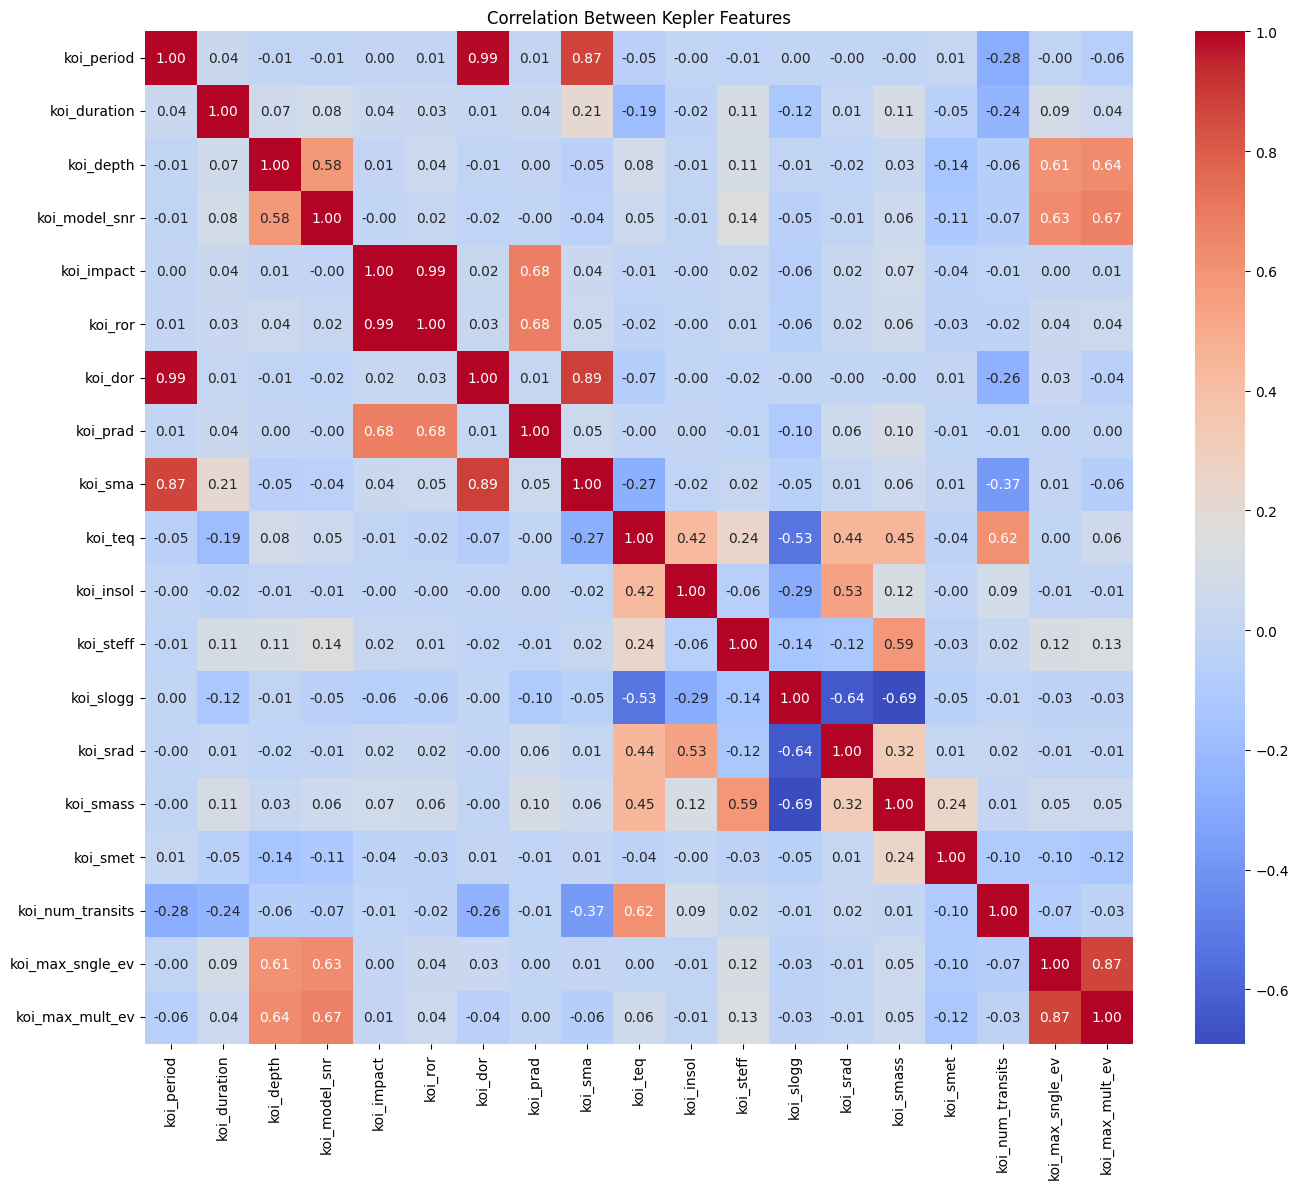

In [15]:

# 7D - Feature Correlation Analysis

# Calculate correlations
correlation_matrix = X_selected.corr()

# Create the figure
plt.figure(figsize=(14, 12))

# Draw correlation heatmap
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

# Add a title
plt.title("Correlation Between Kepler Features")

# Make everything fit
plt.tight_layout()

# Save the figure
plt.savefig("kepler_correlation_heatmap.png", dpi=300)

# Display figure
plt.show()


#### 7D. Findings and Interpretation

The Pearson correlation heatmap reveals several strong relationships among the selected astronomical features.

The strongest positive correlations were observed between `koi_impact` and `koi_ror` (0.99), `koi_period` and `koi_dor` (0.99), and `koi_dor` and `koi_sma` (0.89). Additionally, the two transit detection statistics, `koi_max_sngle_ev` and `koi_max_mult_ev`, exhibited a strong positive correlation of 0.87.

These relationships suggest that certain features may contain overlapping information, potentially introducing redundancy or multicollinearity in some machine-learning models.

We also observed negative correlations between stellar surface gravity (`koi_slogg`) and stellar mass (`koi_smass`), approximately −0.69, and between stellar surface gravity and stellar radius (`koi_srad`), approximately −0.64.

However, the results should be interpreted cautiously. As identified in the previous sections, several variables contain extreme outliers. Since Pearson correlation is sensitive to extreme observations, some correlations may be influenced by a small number of unusually large measurements.

We will retain all 19 features for the initial model and investigate whether highly correlated features affect model performance during subsequent experiments.

#### 7E. Comparing Astronomical Features Across Classification Groups

**Objective:** Investigate whether selected astronomical measurements differ between promising planet observations and false positives.

We compare the distributions of important features across the two classification groups using boxplots.

The features examined include orbital period, transit depth, signal-to-noise ratio, planetary radius, stellar temperature, and transit duration.

This analysis helps us identify potentially informative predictors and understand whether different classes exhibit distinguishable astronomical characteristics.

Because several variables contain extreme values, we focus on comparing their central distributions rather than allowing extreme observations to dominate the visualization.

At this stage, we only compare the measurements. No features or observations are removed.

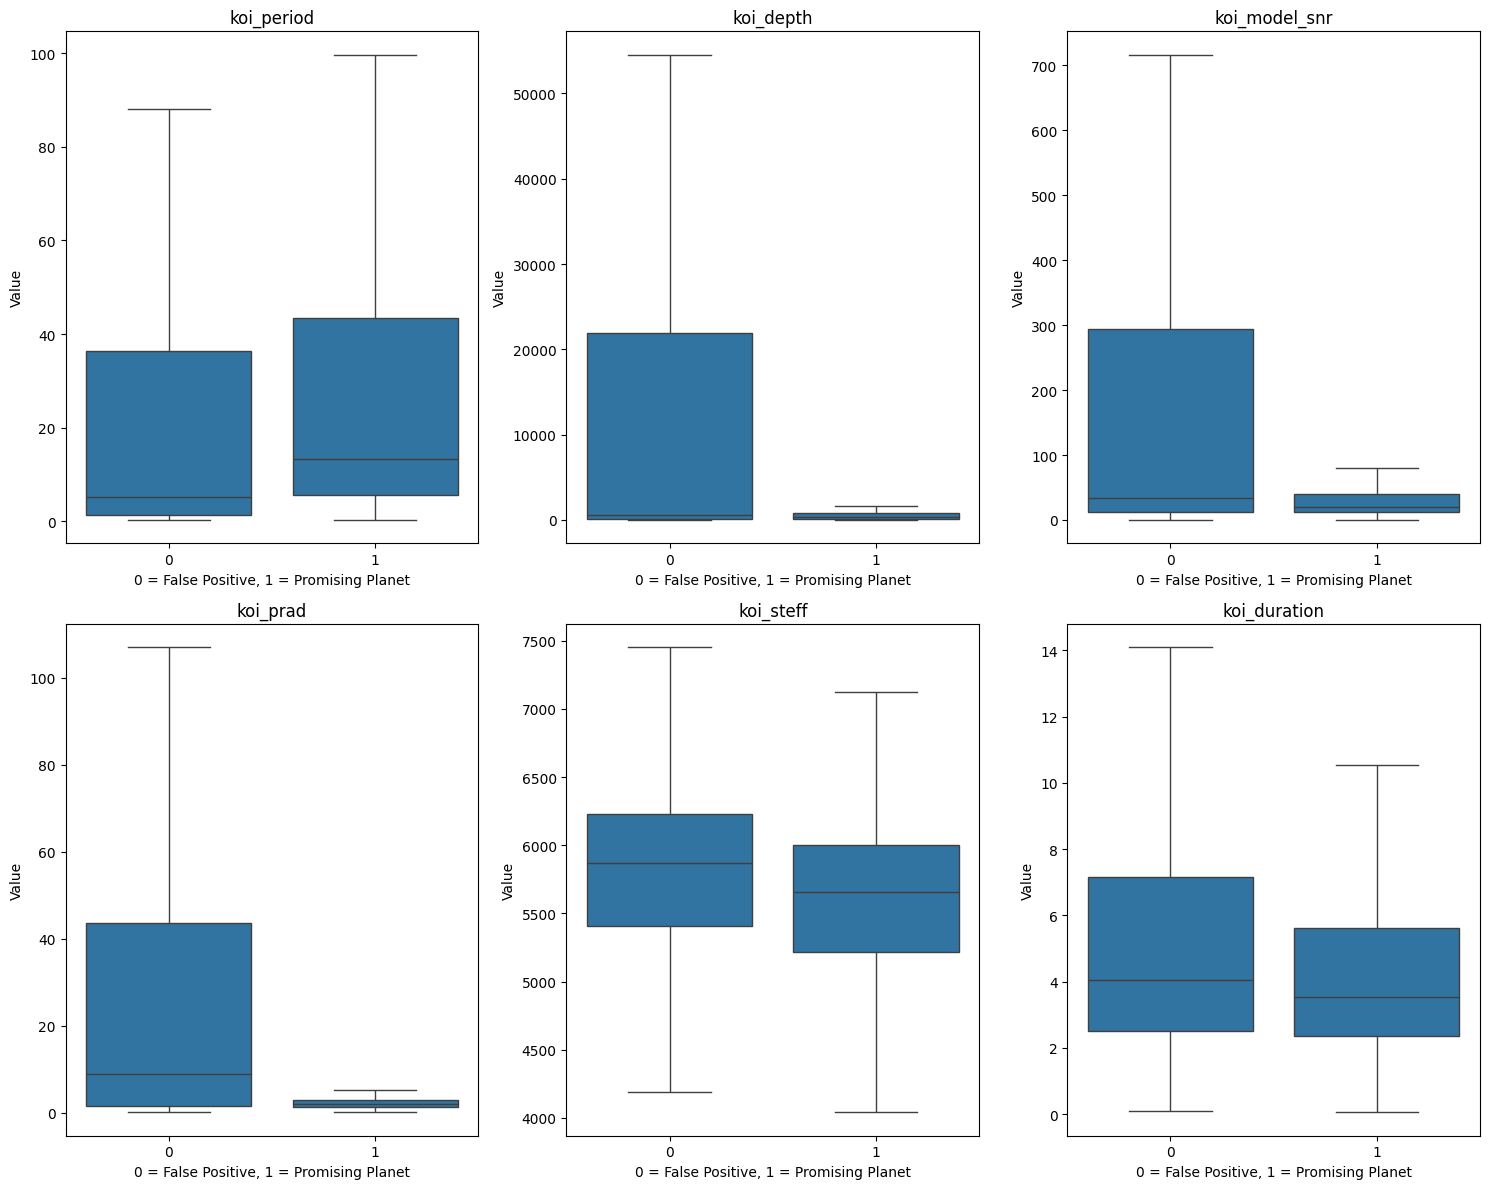

In [16]:

# 7E - Compare features between classes

features_to_compare = [
    "koi_period",
    "koi_depth",
    "koi_model_snr",
    "koi_prad",
    "koi_steff",
    "koi_duration"
]

# Create a dataset for plotting
plot_data = X_selected.copy()
plot_data["target"] = y

plt.figure(figsize=(15, 12))

for i, column in enumerate(features_to_compare):

    plt.subplot(2, 3, i + 1)

    sns.boxplot(
        data=plot_data,
        x="target",
        y=column,
        showfliers=False
    )

    plt.title(column)
    plt.xlabel("0 = False Positive, 1 = Promising Planet")
    plt.ylabel("Value")

plt.tight_layout()
plt.savefig("kepler_class_comparison.png", dpi=300)
plt.show()


#### 7E. Findings and Interpretation

The class-based comparison reveals several differences between promising planet observations and false positives.

Promising planet observations generally exhibit longer orbital periods and smaller estimated planetary radii, while false positives show greater variability in transit depth and signal-to-noise ratio.

One interesting finding is that false positives can produce strong transit signals. This suggests that high signal strength alone is not sufficient to establish whether an observation represents a genuine planetary candidate.

Estimated planetary radius (`koi_prad`) also shows noticeable differences between the classes, with false positives exhibiting larger and more variable values. This may make planetary radius a useful feature for classification.

Stellar temperature (`koi_steff`) and transit duration (`koi_duration`) show smaller differences, with considerable overlap between the two classes.

Overall, these observations suggest that combining multiple astronomical measurements may help distinguish promising planets from false positives more effectively than relying on individual variables.

However, these findings are descriptive and do not yet establish predictive performance. Their usefulness will need to be validated through machine-learning experiments.

#### 7F. Numerical Comparison Between Classification Groups

**Objective:** Quantify differences in astronomical measurements between false positives and promising planet observations.

Following the visual comparisons in Section 7E, we calculate the median value of each selected feature separately for the two classification groups.

We use the median rather than the mean because several features contain extreme values that could distort averages.

This numerical comparison helps confirm the patterns observed in the boxplots and identify variables that may be useful for classification.

No observations are modified or removed during this analysis.

In [17]:

# 7F - Numerical Comparison Between Classes

# Copy the selected dataset
comparison_data = X_selected.copy()

# Add the target column
comparison_data["target"] = y

# Calculate median values for each class
median_comparison = comparison_data.groupby("target").median()

# Switch rows and columns
median_comparison = median_comparison.T

# Rename columns
median_comparison.columns = [
    "False Positive",
    "Promising Planet"
]

# Calculate the difference
median_comparison["Difference"] = (
    median_comparison["Promising Planet"]
    - median_comparison["False Positive"]
)

# Display the table
display(median_comparison.round(2))


,False Positive,Promising Planet,Difference
koi_period,5.24,13.37,8.12
koi_duration,4.06,3.54,-0.52
koi_depth,575.95,356.80,-219.15
koi_model_snr,34.25,19.80,-14.45
koi_impact,0.68,0.39,-0.29
koi_ror,0.04,0.02,-0.02
koi_dor,7.20,22.35,15.16
koi_prad,8.97,2.01,-6.96
koi_sma,0.06,0.11,0.05
koi_teq,1152.50,752.00,-400.50


#### 7F. Findings and Interpretation

The numerical comparison confirms several differences between false positives and promising planet observations.

**Orbital characteristics:** Promising planets have a longer median orbital period (13.37 days) compared with false positives (5.24 days). They also have a larger median orbital separation (`koi_sma`), suggesting that the two groups differ in their observed orbital characteristics.

**Planetary characteristics:** False positives have a substantially larger median estimated planetary radius (8.97 Earth radii) compared with promising planets (2.01 Earth radii). They also exhibit greater median transit depths, suggesting that these measurements may help distinguish the classes.

**Transit signal characteristics:** False positives show higher median signal-to-noise ratios (34.25 versus 19.80) and more recorded transits (268 versus 103). This highlights that stronger or more frequently observed transit signals do not necessarily indicate genuine planetary candidates.

**Stellar and environmental properties:** False positives exhibit higher median equilibrium temperatures and insolation values, while differences in stellar radius, mass, and surface gravity are relatively small in absolute terms.

Overall, these findings suggest that orbital, planetary, and transit signal characteristics may provide useful information for classification. However, substantial overlap between the classes remains, and descriptive differences do not establish predictive performance.

The usefulness of these features will need to be evaluated using machine-learning models and held-out data.

### 8. Train/Test Splitting

#### 8A. Separating Training and Testing Data

**Objective:** Divide the dataset into separate training and testing sets to allow an unbiased evaluation of machine-learning models.

We use 80% of the observations for model development and reserve approximately 20% for final testing.

Because multiple Kepler Objects of Interest may orbit the same host star, we group observations using the stellar identifier (`kepid`). This prevents observations associated with the same star from appearing in both training and testing sets.

The test set will remain untouched during model development. Model selection and hyperparameter tuning will be performed using only the training data and appropriate validation procedures.

Missing-value imputation and any scaling or transformations will be fitted using training data only to prevent data leakage.

In [18]:

# 8A - Train/Test Splitting

from sklearn.model_selection import GroupShuffleSplit

# Create the splitter
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

# Use the star ID to keep observations
# from the same star in one dataset
groups = df["kepid"]

# Get the training and testing row positions
train_index, test_index = next(
    splitter.split(X_selected, y, groups)
)

# Create training data
X_train = X_selected.iloc[train_index].copy()
y_train = y.iloc[train_index].copy()

# Create testing data
X_test = X_selected.iloc[test_index].copy()
y_test = y.iloc[test_index].copy()

# Display dimensions
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)


Training features: (7662, 19)
Testing features: (1902, 19)
Training labels: (7662,)
Testing labels: (1902,)


#### 8B. Train/Test Split Verification

**Objective:** Verify that the training and testing datasets are correctly separated and maintain reasonable class distributions.

Since multiple Kepler observations may belong to the same host star, we check that no stellar identifiers appear in both datasets. This prevents information associated with the same star from being shared between training and testing.

We also examine the distribution of the two target classes in each dataset to ensure that both contain sufficient examples of promising planet observations and false positives.

Finally, we verify that the total number of observations remains unchanged after splitting.

In [19]:

# 8B - Verify Train/Test Split

# Get star IDs for both datasets
train_stars = df.iloc[train_index]["kepid"]
test_stars = df.iloc[test_index]["kepid"]

# Find stars appearing in both datasets
common_stars = set(train_stars) & set(test_stars)

print("Stars appearing in both sets:", len(common_stars))

# Check total number of observations
print("Original observations:", len(df))
print("Train + Test:", len(X_train) + len(X_test))

# Check class distributions
print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTraining class percentages:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting class distribution:")
print(y_test.value_counts())

print("\nTesting class percentages:")
print(y_test.value_counts(normalize=True) * 100)


Stars appearing in both sets: 0
Original observations: 9564
Train + Test: 9564

Training class distribution:
target
0    3858
1    3804
Name: count, dtype: int64

Training class percentages:
target
0    50.352388
1    49.647612
Name: proportion, dtype: float64

Testing class distribution:
target
0    981
1    921
Name: count, dtype: int64

Testing class percentages:
target
0    51.577287
1    48.422713
Name: proportion, dtype: float64


#### 8B. Findings and Interpretation

The train/test split successfully divided the dataset into 7,662 training observations (80.11%) and 1,902 testing observations (19.89%), preserving all 9,564 original observations.

Importantly, no host stars appeared in both datasets, confirming that observations associated with the same star were kept together. This reduces the risk of information leakage between training and testing.

The class distributions remained approximately balanced. The training set contains 50.35% false positives and 49.65% promising planet observations, while the testing set contains 51.58% false positives and 48.42% promising planet observations.

These results indicate that the split preserves the overall class distribution reasonably well while preventing overlap between host stars.

The testing set will be reserved for final evaluation and will not be used for model selection, hyperparameter tuning, or fitting preprocessing transformations.

#### 8C. Final Data Quality Checks

**Objective:** Perform final checks on the training and testing datasets before sharing them for model development.

We verify that all 19 selected features are numerical, check for infinite values, and confirm that no known classification-related variables remain.

We also examine the number of missing values in each dataset to document what the preprocessing pipeline will need to handle.

These checks help ensure that the datasets are consistent and ready for subsequent model training.

Missing values will not be filled at this stage. Median imputation and any necessary scaling will be fitted exclusively using training data during model development.

In [20]:

# 8C - Final Data Quality Checks

import numpy as np

# Check data types
print("Feature data types:")
print(X_train.dtypes)

# Count missing values
print("\nMissing values in training data:")
print(X_train.isna().sum().sum())

print("\nMissing values in testing data:")
print(X_test.isna().sum().sum())

# Count infinite values
train_infinite = np.isinf(X_train).sum().sum()
test_infinite = np.isinf(X_test).sum().sum()

print("\nInfinite values in training data:", train_infinite)
print("Infinite values in testing data:", test_infinite)

# Check for known leakage columns
leakage_check = [
    "koi_disposition",
    "koi_pdisposition",
    "koi_score",
    "koi_fpflag_nt",
    "koi_fpflag_ss",
    "koi_fpflag_co",
    "koi_fpflag_ec",
    "kepler_name"
]

for column in leakage_check:
    if column in X_train.columns:
        print("WARNING: Leakage column found:", column)

print("\nTotal selected features:", X_train.shape[1])


Feature data types:
koi_period          float64
koi_duration        float64
koi_depth           float64
koi_model_snr       float64
koi_impact          float64
koi_ror             float64
koi_dor             float64
koi_prad            float64
koi_sma             float64
koi_teq             float64
koi_insol           float64
koi_steff           float64
koi_slogg           float64
koi_srad            float64
koi_smass           float64
koi_smet            float64
koi_num_transits    float64
koi_max_sngle_ev    float64
koi_max_mult_ev     float64
dtype: object

Missing values in training data:
6717

Missing values in testing data:
1772

Infinite values in training data: 0
Infinite values in testing data: 0

Total selected features: 19


#### 8C. Findings and Interpretation

The final data quality checks confirmed that all 19 selected features are numerical (`float64`) and that neither the training nor testing dataset contains infinite values.

The training dataset contains 6,717 missing entries, while the testing dataset contains 1,772 missing entries. These represent missing feature values rather than the number of incomplete observations.

No known classification-related leakage columns were detected in the selected feature set.

The datasets are therefore ready for the next stage of preprocessing and model development. Missing values have intentionally been preserved so that median imputation can be fitted exclusively using the training data.

Although known leakage variables have been excluded, the remaining derived astronomical measurements may still have limitations related to their original processing and availability.

#### 8D. Exporting the Prepared Datasets

**Objective:** Save the training and testing datasets so that all team members use the same observations, features, and classification labels.

We export the training and testing feature matrices and their corresponding labels as CSV files.

We also save the original Kepler identifiers for each test observation. This allows the error-analysis team to match incorrect predictions to the corresponding astronomical objects and investigate their characteristics.

The exported data retains missing measurements because imputation and scaling will be handled during model training.

These files ensure that the entire group uses a consistent dataset and avoids creating different train/test splits.

In [21]:

# 8D - Export the Datasets

# Save training and testing features
X_train.to_csv("X_train.csv", index=False)
X_test.to_csv("X_test.csv", index=False)

# Save training and testing labels
y_train.to_csv("y_train.csv", index=False)
y_test.to_csv("y_test.csv", index=False)

# Save star IDs for group-aware model validation
train_ids = df.loc[X_train.index, ["kepid", "kepoi_name"]]
test_ids = df.loc[X_test.index, ["kepid", "kepoi_name"]]

train_ids.to_csv("train_ids.csv", index=False)
test_ids.to_csv("test_ids.csv", index=False)

print("All 6 files saved successfully!")


All 6 files saved successfully!


In [22]:

# Download all 6 files together

import zipfile
from google.colab import files

# Create a ZIP file
with zipfile.ZipFile("Kepler_Datasets.zip", "w") as zip_file:
    zip_file.write("X_train.csv")
    zip_file.write("X_test.csv")
    zip_file.write("y_train.csv")
    zip_file.write("y_test.csv")
    zip_file.write("train_ids.csv")
    zip_file.write("test_ids.csv")

# Download the ZIP file
files.download("Kepler_Datasets.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 9. Final Dataset Review and Team Handoff

#### 9A. Final Dataset Verification

**Objective:** Verify that the prepared datasets are consistent and ready to be shared with the other team members.

Before completing the preprocessing notebook, we perform a final verification of the training and testing data.

We check that:

- The training and testing datasets contain the expected number of observations.
- Each feature matrix has a corresponding set of labels.
- Both datasets contain the same 19 scientific features.
- No host stars appear in both datasets.
- The exported files are available for model development.

These checks help ensure that the datasets can be used consistently during model training, evaluation, and error analysis.

In [23]:

# 9A - Final Dataset Verification

import os

# Check that features and labels match
print("Training rows match:", len(X_train) == len(y_train))
print("Testing rows match:", len(X_test) == len(y_test))

# Check that the features are identical
print("Same features:", list(X_train.columns) == list(X_test.columns))

# Check the number of features
print("Number of features:", X_train.shape[1])

# Check overlapping stars
train_stars = set(train_ids["kepid"])
test_stars = set(test_ids["kepid"])

print("Overlapping stars:", len(train_stars & test_stars))

# Check exported files
file_names = [
    "X_train.csv",
    "X_test.csv",
    "y_train.csv",
    "y_test.csv",
    "train_ids.csv",
    "test_ids.csv"
]

for name in file_names:
    print(name, "exists:", os.path.exists(name))


Training rows match: True
Testing rows match: True
Same features: True
Number of features: 19
Overlapping stars: 0
X_train.csv exists: True
X_test.csv exists: True
y_train.csv exists: True
y_test.csv exists: True
train_ids.csv exists: True
test_ids.csv exists: True


#### 9B. Preprocessing Summary and Handoff

**Objective:** Summarize the completed data preparation work and document the decisions relevant to subsequent model development.

The NASA Kepler dataset initially contained 9,564 observations and 153 variables. A binary target was created by combining confirmed planets and candidates into one class and assigning false positives to the other.

Classification-related variables, identifiers, and selected metadata were excluded to reduce the risk of data leakage. A set of 19 numerical astronomical features was retained for the initial classification experiments.

Exploratory analysis revealed skewed feature distributions, extreme fitted measurements, correlated variables, and differences between the classification groups.

The dataset was split using host-star identifiers to prevent observations associated with the same star from appearing in both training and testing sets.

Missing measurements were preserved. Median imputation and any necessary scaling will be fitted on training data during model development.

The resulting datasets have been exported for use by the model-development and error-analysis team members.